In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import os

In [2]:
## %pip install openpyxl

In [3]:
print(os.getcwd())

D:\Customer_Segmentation_BI\notebooks


In [4]:
df = pd.read_csv('../data/Online Retail.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [5]:
df.sample(6)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
330542,565919,22905,CALENDAR IN SEASON DESIGN,1,07-09-2011 16:48,2.46,NaN,United Kingdom
86304,543543,85020,ROUND PINK HEART MIRROR,2,09-02-2011 15:33,2.10,17843.0,United Kingdom
344685,567094,23208,LUNCH BAG VINTAGE LEAF DESIGN,4,16-09-2011 12:54,1.65,16924.0,United Kingdom
104752,545215,21181,PLEASE ONE PERSON METAL SIGN,1,28-02-2011 16:47,4.13,NaN,United Kingdom
40049,539718,85114B,IVORY ENCHANTED FOREST PLACEMAT,3,21-12-2010 13:06,3.36,NaN,United Kingdom
461900,575954,22113,GREY HEART HOT WATER BOTTLE,4,13-11-2011 12:03,4.25,17211.0,United Kingdom


In [6]:
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    dayfirst=True
)

In [7]:
print(df['InvoiceDate'].dtype)
print(df['InvoiceDate'].head())

datetime64[ns]
0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[ns]


In [8]:
df['Country'].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Bahrain', 'Greece', 'Hong Kong', 'Singapore',
       'Lebanon', 'United Arab Emirates', 'Saudi Arabia',
       'Czech Republic', 'Canada', 'Unspecified', 'Brazil', 'USA',
       'European Community', 'Malta', 'RSA'], dtype=object)

In [9]:
df['Country'].value_counts().sort_index()


Country
Australia                 1259
Austria                    401
Bahrain                     19
Belgium                   2069
Brazil                      32
Canada                     151
Channel Islands            758
Cyprus                     622
Czech Republic              30
Denmark                    389
EIRE                      8196
European Community          61
Finland                    695
France                    8557
Germany                   9495
Greece                     146
Hong Kong                  288
Iceland                    182
Israel                     297
Italy                      803
Japan                      358
Lebanon                     45
Lithuania                   35
Malta                      127
Netherlands               2371
Norway                    1086
Poland                     341
Portugal                  1519
RSA                         58
Saudi Arabia                10
Singapore                  229
Spain                     2533


In [10]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [11]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [12]:
df['Description'].head()


0     WHITE HANGING HEART T-LIGHT HOLDER
1                    WHITE METAL LANTERN
2         CREAM CUPID HEARTS COAT HANGER
3    KNITTED UNION FLAG HOT WATER BOTTLE
4         RED WOOLLY HOTTIE WHITE HEART.
Name: Description, dtype: object

In [13]:
df['Description'].value_counts()

Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
                                      ... 
ANT SILVER TURQUOISE BOUDICCA RING       1
Damages                                  1
Found by jackie                          1
water damaged                            1
lost in space                            1
Name: count, Length: 4223, dtype: int64

In [14]:
df['Description'].unique()


array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ..., 'lost',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], shape=(4224,), dtype=object)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [16]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [34]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


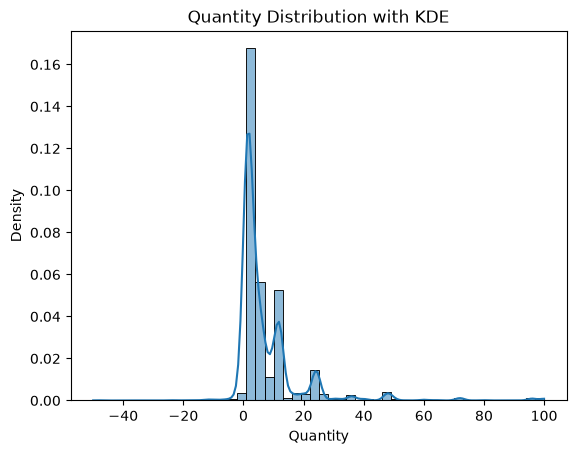

In [17]:
sample = df['Quantity'].sample(n=50000, random_state=42)

plot_data = sample[(sample >= -50) & (sample <= 100)]

sns.histplot(
    x=plot_data,
    bins=50,
    kde=True,
    stat='density'
)

plt.title('Quantity Distribution with KDE')
plt.xlabel('Quantity')
plt.show()

In [18]:
print("Mean:", df['Quantity'].mean())
print("Median:", df['Quantity'].median())
print("Skewness:", df['Quantity'].skew())

Mean: 9.55224954743324
Median: 3.0
Skewness: -0.2640763070668848


In [19]:
print("lowest quantities")

print(df['Quantity'].nsmallest(10))

print("\nlargest quantities")
print(df['Quantity'].nlargest(10))



lowest quantities
540422   -80995
61624    -74215
225529    -9600
225530    -9600
4287      -9360
225528    -9058
115818    -5368
431381    -4830
341601    -3667
323458    -3167
Name: Quantity, dtype: int64

largest quantities
540421    80995
61619     74215
502122    12540
74614      5568
421632     4800
206121     4300
220843     4000
97432      3906
270885     3186
52711      3114
Name: Quantity, dtype: int64


In [20]:
extreme_rows = df.loc[
    df['Quantity'].abs() >= 50000
]

display(
    extreme_rows[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'InvoiceDate', 'UnitPrice',
         'CustomerID', 'Country']
    ]
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


In [21]:
df['InvoiceNo'].value_counts()

InvoiceNo
573585     1114
581219      749
581492      731
580729      721
558475      705
           ... 
581483        1
581566        1
C581499       1
C536383       1
C536379       1
Name: count, Length: 25900, dtype: int64

In [22]:
df['InvoiceNo'] =df['InvoiceNo'].astype(str)  


In [23]:
df['IsCancelled'] = df['InvoiceNo'].str.startswith('C')

In [24]:
df['IsCancelled'].value_counts()

IsCancelled
False    532621
True       9288
Name: count, dtype: int64

In [25]:
print(df['IsCancelled'].value_counts())
print(df['IsCancelled'].value_counts(normalize=True).mul(100).round(2))

IsCancelled
False    532621
True       9288
Name: count, dtype: int64
IsCancelled
False    98.29
True      1.71
Name: proportion, dtype: float64


In [26]:
print(df['InvoiceNo'].head(10).tolist())
print("\nInvoice numbers starting with C:")
print(df[df['InvoiceNo'].str.startswith('C')]['InvoiceNo'].head(10))

['536365', '536365', '536365', '536365', '536365', '536365', '536365', '536366', '536366', '536367']

Invoice numbers starting with C:
141    C536379
154    C536383
235    C536391
236    C536391
237    C536391
238    C536391
239    C536391
240    C536391
241    C536391
939    C536506
Name: InvoiceNo, dtype: object


In [27]:
import pandas as pd

df = pd.read_csv(
    '../data/Online Retail.csv',
    dtype={'InvoiceNo': str}
)

df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    dayfirst=True
)

print(df['InvoiceNo'].head(10).tolist())

['536365', '536365', '536365', '536365', '536365', '536365', '536365', '536366', '536366', '536367']


In [28]:
df['IsCancelled'] = df['InvoiceNo'].str.startswith('C')

print(df['IsCancelled'].value_counts())

print(
    df['IsCancelled']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

IsCancelled
False    532621
True       9288
Name: count, dtype: int64
IsCancelled
False    98.29
True      1.71
Name: proportion, dtype: float64


In [29]:
display(
    df.loc[
        df['IsCancelled'],
        ['InvoiceNo', 'Quantity', 'InvoiceDate', 'CustomerID']
    ].head(10)
)

,InvoiceNo,Quantity,InvoiceDate,CustomerID
141,C536379,-1,2010-12-01 09:41:00,14527.0
154,C536383,-1,2010-12-01 09:49:00,15311.0
235,C536391,-12,2010-12-01 10:24:00,17548.0
236,C536391,-24,2010-12-01 10:24:00,17548.0
237,C536391,-24,2010-12-01 10:24:00,17548.0
238,C536391,-24,2010-12-01 10:24:00,17548.0
239,C536391,-12,2010-12-01 10:24:00,17548.0
240,C536391,-12,2010-12-01 10:24:00,17548.0
241,C536391,-24,2010-12-01 10:24:00,17548.0
939,C536506,-6,2010-12-01 12:38:00,17897.0


In [35]:
# Find invoice numbers that contain any letters
invoice_text = df['InvoiceNo'].astype(str)

letter_invoices = invoice_text[
    invoice_text.str.contains(r'[A-Za-z]', regex=True, na=False)
]

print("Rows with letters:", len(letter_invoices))
print("\nLetter-containing invoice examples:")
print(letter_invoices.drop_duplicates().head(30).tolist())

print("\nDistinct letter prefixes:")
print(
    letter_invoices.drop_duplicates()
    .str.extract(r'^([A-Za-z]+)')[0]
    .value_counts()
)

Rows with letters: 9291

Letter-containing invoice examples:
['C536379', 'C536383', 'C536391', 'C536506', 'C536543', 'C536548', 'C536606', 'C536622', 'C536625', 'C536642', 'C536734', 'C536737', 'C536757', 'C536758', 'C536760', 'C536807', 'C536812', 'C536814', 'C536815', 'C536816', 'C536817', 'C536818', 'C536820', 'C536822', 'C536825', 'C536826', 'C536827', 'C536828', 'C536829', 'C536850']

Distinct letter prefixes:
0
C    3836
A       3
Name: count, dtype: int64


In [36]:
# Find invoice numbers that start with A
a_invoices = invoice_text[
    invoice_text.str.startswith('A', na=False)
]

# Display the distinct A-prefixed invoice numbers
print(a_invoices.drop_duplicates().tolist())

# Inspect the corresponding transaction details
display(
    df.loc[
        df['InvoiceNo'].isin(a_invoices),
        [
            'InvoiceNo',
            'StockCode',
            'Description',
            'Quantity',
            'InvoiceDate',
            'UnitPrice',
            'CustomerID'
        ]
    ].drop_duplicates()
)

['A563185', 'A563186', 'A563187']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN


In [37]:
df['CustomerID'].isnull().sum()

np.int64(135080)

In [38]:
print("Missing CustomerID values:", df['CustomerID'].isna().sum())

Missing CustomerID values: 135080


In [39]:
missing_percentage=(df['CustomerID'].isnull().mean()*100).round(2)
missing_percentage

np.float64(24.93)

In [40]:
print(df['CustomerID'].notna().value_counts())

CustomerID
True     406829
False    135080
Name: count, dtype: int64


In [41]:
print("Negative quantity rows: ", (df['Quantity']<0).sum())

Negative quantity rows:  10624


In [43]:
print("Zero quantity rows: ", (df['Quantity']==0).sum())


Zero quantity rows:  0


In [44]:
print("Negative unit price rows:", (df['UnitPrice'] < 0).sum())

Negative unit price rows: 2


In [45]:
display(
    pd.crosstab(
        df['InvoiceNo'].str.startswith('C', na=False),
        df['Quantity'] < 0,
        rownames=['Cancellation prefix'],
        colnames=['Negative quantity']
    )
)

Negative quantity,False,True
Cancellation prefix,,
False,531285,1336
True,0,9288


In [48]:
negative_without_c = df[
    (df['Quantity']<0) &
    (~df['InvoiceNo'].str.startswith('C',na=False))
]

In [49]:
display(
    negative_without_c[[ 'InvoiceNo',
            'StockCode',
            'Description',
            'Quantity',
            'InvoiceDate',
            'UnitPrice',
            'CustomerID',
            'Country']].head(20)
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [51]:
ends_with_c = df['InvoiceNo'].str.endswith("C",na=False)

In [52]:
print(
    df.loc[ends_with_c, 'InvoiceNo']
    .drop_duplicates()
    .head(20)
    .tolist()
)

[]


In [53]:
print("Starts with C:",df["InvoiceNo"].str.startswith("C",na=False).sum())
print("Ends with C:",df["InvoiceNo"].str.endswith("C",na=False).sum())
print("Contains any letter:",df["InvoiceNo"].str.contains(r'[A-Za-z]',regex=True,na=False).sum())



Starts with C: 9288
Ends with C: 0
Contains any letter: 9291


In [59]:
# 1. Filter negative-quantity rows without a C prefix
negative_without_c = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].str.startswith("C", na=False))
]

# 2. Count missing customer IDs
print(
    "Missing CustomerID:",
    negative_without_c["CustomerID"].isna().sum()
)

# 3. Find the most common descriptions
print("\nMost common descriptions:")
print(
    negative_without_c["Description"]
    .value_counts(dropna=False)
    .head(15)
)

# 4. Find the most common invoice numbers
print("\nMost common invoice numbers:")
print(
    negative_without_c["InvoiceNo"]
    .value_counts()
    .head(15)
)

Missing CustomerID: 1336

Most common descriptions:
Description
NaN                       862
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
ebay                        5
wet damaged                 5
smashed                     4
CHECK                       3
Name: count, dtype: int64

Most common invoice numbers:
InvoiceNo
581422    1
536589    1
536764    1
536996    1
536997    1
536998    1
537000    1
537001    1
580990    1
580561    1
580547    1
580546    1
580383    1
580382    1
580381    1
Name: count, dtype: int64


In [60]:
# Find negative-quantity rows with a known CustomerID
negative_with_customer = df[
    (df["Quantity"] < 0) &
    (df["CustomerID"].notna())
]

print("Negative quantity rows with CustomerID:",
      len(negative_with_customer))

print("\nMost common descriptions:")
print(
    negative_with_customer["Description"]
    .value_counts(dropna=False)
    .head(15)
)

print("\nSample transactions:")
display(
    negative_with_customer[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID"
        ]
    ].head(20)
)

Negative quantity rows with CustomerID: 8905

Most common descriptions:
Description
REGENCY CAKESTAND 3 TIER              181
Manual                                175
POSTAGE                                97
JAM MAKING SET WITH JARS               86
Discount                               77
SET OF 3 CAKE TINS PANTRY DESIGN       73
STRAWBERRY CERAMIC TRINKET BOX         55
ROSES REGENCY TEACUP AND SAUCER        53
RECIPE BOX PANTRY YELLOW DESIGN        47
WOOD 2 DRAWER CABINET WHITE FINISH     45
JUMBO BAG RED RETROSPOT                44
WHITE HANGING HEART T-LIGHT HOLDER     42
GREEN REGENCY TEACUP AND SAUCER        42
LUNCH BAG RED RETROSPOT                42
RED RETROSPOT CAKE STAND               41
Name: count, dtype: int64

Sample transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0


In [61]:
# Check customer ID availability against cancellation prefix
display(
    pd.crosstab(
        df['InvoiceNo'].str.startswith('C', na=False),
        df['CustomerID'].isna(),
        rownames=['Starts with C'],
        colnames=['CustomerID missing']
    )
)

CustomerID missing,False,True
Starts with C,,
False,397924,134697
True,8905,383


In [62]:
# Inspect rows with unusual transaction descriptions
keywords = r'DISCOUNT|MANUAL|POSTAGE|ADJUST BAD DEBT'

unusual_lines = df[
    df['Description'].str.contains(
        keywords,
        case=False,
        na=False,
        regex=True
    )
]

print("Matching transaction rows:", len(unusual_lines))

display(
    unusual_lines[
        [
            'InvoiceNo',
            'StockCode',
            'Description',
            'Quantity',
            'InvoiceDate',
            'UnitPrice',
            'CustomerID'
        ]
    ].head(25)
)

Matching transaction rows: 2613


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583.0
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791.0
1123,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662.0
1814,536544,DOT,DOTCOM POSTAGE,1,2010-12-01 14:32:00,569.77,NaN
2239,536569,M,Manual,1,2010-12-01 15:35:00,1.25,16274.0
2250,536569,M,Manual,1,2010-12-01 15:35:00,18.95,16274.0
3041,536592,DOT,DOTCOM POSTAGE,1,2010-12-01 17:06:00,607.49,NaN
5073,536840,POST,POSTAGE,1,2010-12-02 18:27:00,18.00,12738.0
5258,536852,POST,POSTAGE,1,2010-12-03 09:51:00,18.00,12686.0


In [63]:
# Count transaction rows for each matching description
print(
    unusual_lines['Description']
    .value_counts(dropna=False)
    .head(30)
)

Description
POSTAGE            1252
DOTCOM POSTAGE      709
Manual              572
Discount             77
Adjust bad debt       3
Name: count, dtype: int64


In [67]:
purchases = df.copy()

## keeping known customer ids
purchases = purchases[purchases['CustomerID'].notna()]

## keeping non negative quantity and unit price
purchases = purchases[
    (purchases['Quantity']>0) &
    (purchases['UnitPrice']>0)
]

##excluding cancellation prefix invoices
purchases = purchases[
    ~purchases['InvoiceNo'].str.startswith("C",na=False)
]

 #5. Exclude non-product transaction descriptions
excluded_descriptions = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'Manual',
    'Discount',
    'Adjust bad debt'
]

purchases = purchases[
    ~purchases["Description"].isin(excluded_descriptions)
]

 ## Calculate the value of each remaining transaction line
purchases['LineValue'] = (
    purchases['Quantity'] * purchases['UnitPrice']
)

# 7. Inspect the result
print("Original rows:", len(df))
print("Cleaned purchase rows:", len(purchases))
print("Unique customers:", purchases['CustomerID'].nunique())

display(purchases.head())

Original rows: 541909
Cleaned purchase rows: 396485
Unique customers: 4335


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34


In [68]:
print("Rows remaining:", len(purchases))
print("Unique customers:", purchases['CustomerID'].nunique())

print("\nMissing customer IDs:")
print(purchases['CustomerID'].isna().sum())

print("\nNegative quantities:")
print((purchases['Quantity'] < 0).sum())

print("\nNon-positive unit prices:")
print((purchases['UnitPrice'] <= 0).sum())

print("\nCancelled invoices:")
print(purchases['InvoiceNo'].str.startswith('C', na=False).sum())

print("\nDuplicate rows:")
print(purchases.duplicated().sum())

Rows remaining: 396485
Unique customers: 4335

Missing customer IDs:
0

Negative quantities:
0

Non-positive unit prices:
0

Cancelled invoices:
0

Duplicate rows:
5187


In [69]:
# Count all rows that have an identical earlier row
print("Duplicate rows:", purchases.duplicated().sum())

# Display the first 20 duplicate rows
display(
    purchases[purchases.duplicated(keep=False)]
    .sort_values(
        ['InvoiceNo', 'StockCode', 'CustomerID']
    )
    .head(20)
)


Duplicate rows: 5187


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,LineValue
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,1.25
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,1.25
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,4.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,4.95
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,2.10
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,2.10
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,2.95
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,2.95
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,False,3.30
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,False,1.65


In [70]:
# Count rows belonging to duplicated groups
duplicate_mask = purchases.duplicated(keep=False)

print("Rows belonging to duplicate groups:", duplicate_mask.sum())

# Count duplicate occurrences beyond the first copy
print("Extra duplicate occurrences:", purchases.duplicated().sum())

# Count unique rows after removing exact duplicates (for comparison only)
print("Rows after hypothetical deduplication:",
      len(purchases.drop_duplicates()))

Rows belonging to duplicate groups: 9995
Extra duplicate occurrences: 5187
Rows after hypothetical deduplication: 391298
